<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    LNDb - Lung Nodule Database
  </h1>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    A datased based on LIDC-IDRI
  </h3>

  <p>
   The LNDb was developed as an external dataset complimentary to LIDC-IDRI. There are a few important differences between the two... While LIDC-IDRI is a project shared between 7 institutions, LNDb is a smaller dataset, belonging to a single institution - Centro Hospitalar e Universitário de São João (CHUSJ) in Porto.
  </p>
  <p>
   LNDb contains 294 CT scans - about a quarter of the size of LIDC-IDRI, and its classification method is different as well: it uses a single-blind methodology (a radiologist would read the scan once and no consensus or review between the radiologists was performed), instead of having multiple radiologists reading the same scan. This might cause a noticeable distinction in classification pattern for each radiologist; but, unlike LIDC-IDRI, the 5 participant radiologists are identified uniformly throughout the dataset as R1, R2, R3, R4 and R5.
  </p>
  <p>
   The variability in acquisition parameters is significantly lower in LNDb, as well as the subjective characterization of nodules. LNDb is overall a more clinically realistic dataset.
   </p>
  
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Initial Data Analysis & Pre-Processing
  </h3>

  <p>
    To access LNDb's auxiliary functions, which will help us to visualize, understand and manipulate data, we must import the script <strong>'utils.py'</strong> and other scripts made available with the download of the dataset.
  </p>
  <p>
    The first step in our analysis of the dataset is to ensure that we can read the MetaImage <strong>.mhd/.raw</strong> medical image files - both the Computerized Tomography (CT) data and the segmentation masks are in this format. The file <strong>'utils.py'</strong> includes routines based on the SimpleITK library that allow us to... 
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Load the 3D CT images and the nodule masks.</li>
    <li style="margin-bottom: 8px;">Extract the metadata from the medical images, such as the pixel/voxel spacing, the origin and the orientation matrix of the CT.</li>
  </ol>
  <p>
    We also want to match scan slices to nodule coordinates. Thus, we have created a reusable function <strong>read_nods_in_scan</strong> which, for one scan metadata file LNDb-XXXX.mhd, and its corresponding image LNDb-XXXX.raw, extracts the necessary information for coordinate conversion from milimeters into pixels/voxels and vice-versa. This is possible using the origin, the spacing and transformation matrix of the scan. 
  </p>
  <p>
    This function also reads the nodule coordinates, in milimeters, and converts them to image coordinates, in pixel / cut indexes, using the origin and transformation origin of the corresponding scan. This way, we can associate these coordinates with the scan image. It also repeats the process for the nodule mask. So, we are able to quickly visualize every node and its mask in each CT Scan!
  </p>
</div>

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from contextlib import redirect_stdout
import ast

root_path = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(root_path) not in sys.path: sys.path.append(str(root_path))

from src.mass_detect.lndb_utils import utils
from src.mass_detect.lndb_utils.readNoduleList import nodEqDiam
from src.mass_detect.lndb_utils.calcFleischner import calcFleischner
from src.mass_detect.scripts.lndb_exploration_utils import *

train_nodules = pd.read_csv(find_file("trainNodules.csv"))
ct_scan_id = 1
scan, spacing, origin, nods_scan = read_nods_in_scan(ct_scan_id, train_nodules)

print(f"The CT Scan {ct_scan_id} has...\n  -> dimensions {scan.shape}\n  -> origin {origin}\n  -> spacing {spacing}\n")
print(f"For this scan, we have {len(nods_scan)} findings:")
print(nods_scan[['LNDbID', 'RadID', 'FindingID', 'x_img', 'y_img', 'z_img']])

KeyboardInterrupt: 

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    By the shape of the scan array, we can conclude that it has 328 cuts of 512x512 pixels. The voxel spacing (0.607, 0.607, 1.0)mm shows that the volume <strong>is not isotropic</strong> because the plane resolution is thinner than in between cuts. This is something to have in mind if we decide to resample into a uniform spacing before feature extraction - this probably makes the most sense. 
  </p>
  <div style="background-color: #c25719; padding: 2px 10px; border-radius: 0px; margin: 0px -10px;">
    <strong style="color: #1967d2;">Note:</strong> An isotropic volume implies that the spacing between voxels is equal in all directions (x, y, z) - in other words, each voxel is shaped like a perfect cube.
  </div>
  <p>
    Lastly, the origin indicates the coordinate of the word corresponding to the volume corner, necessary to convert nodule coordinates in further steps.
  </p>
  <p>
    Now, we must confirm visually the coordinate conversion by showing the exact cut where the nodule was annotated, with a red <strong>X</strong> in its position. Below, there is the side-by-side comparison of the original image and the annotated image with its nodules.
  </p>
</div>

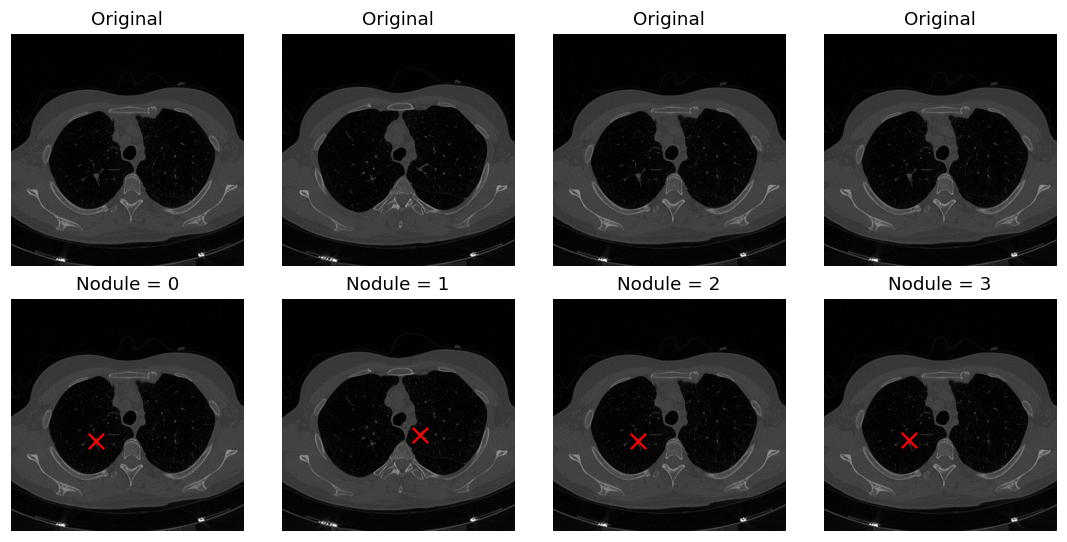

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i in range(len(nods_scan)):
    axes[0][i].imshow(scan[int(nods_scan['z_img'].iloc[i])], cmap='gray')
    axes[0][i].set_title(f"Original")
    axes[0][i].axis("off")  # Hides x and y tick marks
    axes[1][i].imshow(scan[int(nods_scan['z_img'].iloc[i])], cmap='gray')
    axes[1][i].set_title(f"Nodule = {i}")
    axes[1][i].scatter(nods_scan['x_img'].iloc[i], nods_scan['y_img'].iloc[i], c='red', marker='x', s=100)  # marca a posição do nódulo
    axes[1][i].axis("off")
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    By comparing the original CT slice with the annotated nodule, we confirm that it does, indeed, correspond to the location of a nodule. However, for this CT Scan, we also understand that nodules 0, 2 and 3 are the same - they were simply marked by 3 different radiologists. This can be confirmed both by their 'FindingID' and by taking a closer look at the nodules. The <strong>'utils.py'</strong> module has a function which extracts a small region of an image (typically 80x80x80 voxels) surrounding a central point. This makes it very easy to get a centered image of each nodule!
  </p>
</div>

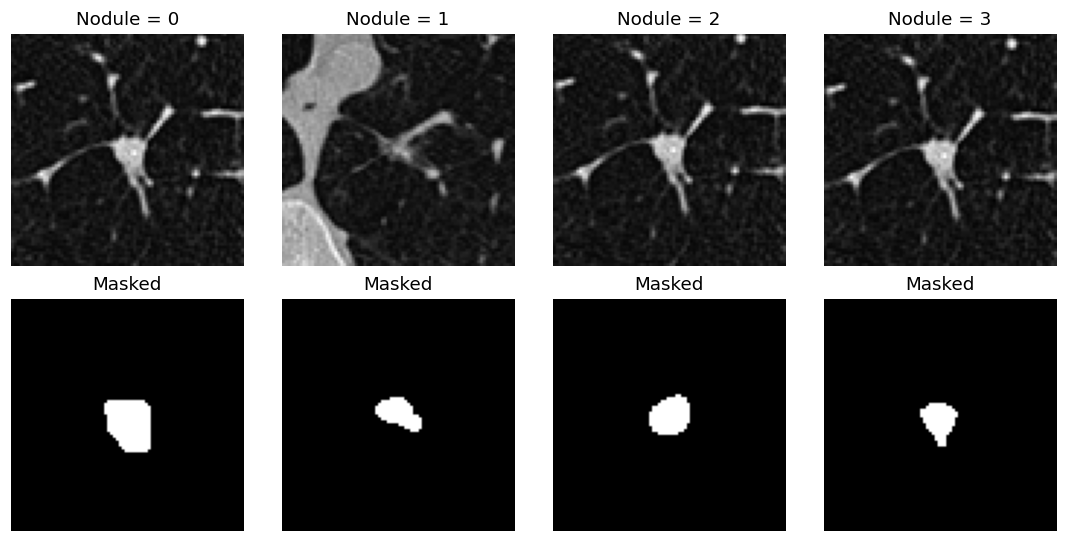

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i in range(len(nods_scan)):
    cube = utils.extractCube(scan, spacing, (nods_scan['x_img'].iloc[i], nods_scan['y_img'].iloc[i], nods_scan['z_img'].iloc[i]))
    mask_cube = utils.extractCube(nods_scan['mask'].iloc[i], spacing, (nods_scan['x_img'].iloc[i], nods_scan['y_img'].iloc[i], nods_scan['z_img'].iloc[i]))
    axes[0][i].imshow(cube[cube.shape[0]//2], cmap='gray')
    axes[0][i].set_title(f"Nodule = {i}")
    axes[0][i].axis("off")  # Hides x and y tick marks
    axes[1][i].imshow(mask_cube[mask_cube.shape[0]//2], cmap = 'gray')
    axes[1][i].set_title(f"Masked")
    axes[1][i].axis("off")

plt.tight_layout()
plt.show() 

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    And, as it is very clear now, there are 3 repeated nodules. This repetitions happens because the file <strong>'trainNodules.csv'</strong> has an entry for each finding made by a radiologist. So, if many radiologists annotate the same nodule, there are many rows corresponding to that node in the file. The radiologists annotated the nodule's mask pretty differently, even if it is exactly the same nodule. This is, actually, an important part of our pre-processing: we must decide how to deal with different subjective annotations for the same nodule.
  </p>
  <p>
    This repetition of the same nodule also happens in another file available in our dataset: <strong>chars_trainNodules.csv</strong>. In fact, these two complement eachother! The first stores the (x, y, z) coordinates of each finding, the nodule classification (nodule / non-nodule) and the volume and texture (necessary for calculating Fleischner Score). The second stores the subjective characteristics of each nodule (calcification, internal structure, malignancy, ...). So, it is a good idea to join them in one single file.
  </p>
  <p>
    However, there is a small detail to take into account - there is disparity line-wise in these files. <strong> chars_trainNodules.csv</strong> contains records from all 5 radiologists, while <strong>trainNodules.csv</strong> only contains records from radiologists 1, 2 and 3. This happens because, in the second file, the 'RadID' is relative to the CT Scan, and not to the overall ID of the radiologist. This can be handled by simply merging both tables while deleting duplicate columns and keeping the correct 'RadID_Real' relative to the overall radiologist ID instead of to the CT scan radiologist ID.
  </p>
</div>

In [ ]:
char_train= pd.read_csv(find_file('chars_trainNodules.csv'))
train = pd.read_csv(find_file('trainNodules.csv'))

# Positional join: only valid if lines correspond to the same finding
assert len(train) == len(char_train)
assert (train[['LNDbID', 'FindingID']].values == char_train[['LNDbID', 'FindingID']].values).all()

combined_df = pd.concat([train, char_train.drop(columns=['LNDbID', 'FindingID']).rename(columns={'RadID': 'RadID_real'})],axis=1,)
combined_df['RadID_real'] = combined_df['RadID_real'].astype(int)

# 'outer' keeps all entries, 'inner' keeps only nodules present in both.
#combined_df = pd.merge(train, char_train, on=['LNDbID', 'RadID', 'FindingID'], how="outer")

print(combined_df.shape)
print(" | ".join(combined_df.columns))

(1527, 18)
LNDbID | RadID | FindingID | x | y | z | Nodule | Volume | Text | RadID_real | calcification | internalStructure | lobulation | malignancy | margin | sphericity | spiculation | subtlety


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Now, let us take a moment to understand the meaning of each column in our dataframe. We must have a clear understanding of our data so that we can make better processing choices and achieve better accuracy on our final predictions.
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Each line corresponds to a finding <strong style="color: #c25719;">FindingID</strong> marked by a radiologist <strong style="color: #c25719;">RadID_Real</strong> in a scan <strong style="color: #c25719;">LNDbID</strong>.</li>
    <li style="margin-bottom: 8px;">We have the coordinates <strong style="color: #c25719;">x</strong>, <strong style="color: #c25719;">y</strong> and <strong style="color: #c25719;">z</strong> of our finding.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Nodule</strong> is 1 if the finding is a nodule, and 0 if it is not.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Volume</strong> is the physical 3D volume of the annotated pulmonary lesion, measured in cubic millimeters.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Text</strong> refers to the texture of the nodule, and, combined with Volume, allows for Fleischner Score calculations.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Calcification</strong> refers to calcium deposits inside the nodule. Calcifications can be concentric rings, as well as off-centered or tiny scattered specks.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Internal Structure</strong> describes what the inside of the nodule consists of; specifically, its tissue density and components. It can be <strong>solid</strong>, <strong>subsolid</strong>, <strong>part-solid</strong>... Also, <strong>fat</strong> inside a nodule strongly favors a benign hamartoma, while <strong>cavitations</strong> warrant careful evaluation.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Lobulation</strong> refers to a wave-like outer contour instead of a smooth circle. Lobulated margins occur due to uneven growth rates in different parts of the nodule.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Malignancy</strong> categorizes on a scale from 1 to 5 the overall probability that the nodule is cancerous based on size, growth rate and physical features.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Margin</strong> is the general appearance of the border where the nodule meets normal lung tissue. It can be <strong>smooth/well-defined</strong> or <strong>ill-defined/irregular</strong>.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Sphericity</strong> measures how closely the nodule resembles a 3D sphere versus an elongated or flat shape.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Spiculation</strong> refers to strands or "spikes" radiating outward from the edge of the nodule into surrounding lung tissue, giving it a starburst appearance.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Subtlety</strong> indicates how easy or difficult the nodule is to visually distinguish from surrounding structures (like normal blood vessels, chest wall, or diaphragm).</li>
  </ul>
  <p>
    However, these two files that we have just merged together are not the only ones - we have another file, <strong>allNods.csv</strong>. It is grouped by independent nodule. However, the information available in this file is very focused on the text reports, adding little information about the CT Scans. There is one new column which can be valuable to us: <strong>'Lobe'</strong> column tells us where a nodule is located in the lung. So, we can consider this column for our model's predictions. 
  </p>
  <p>
    Let us extract the useful information from <strong>allNods.csv</strong>, by removing text report lines and extracting our column of interest, <strong>'Lobe'</strong>. To merge this column with our other files, we must take into account the fact that this file groups annotations by independent nodule.
  </p>
</div>

In [ ]:
all_nods = pd.read_csv(find_file('allNods.csv'))
all_nods = all_nods[all_nods['Where'].str.contains("RadAnnotation", na=False)]
all_nods = all_nods[['LNDbID', 'FindingID', 'Lobe']]

combined_df = combined_df.merge(
    all_nods[["LNDbID", "FindingID", "Lobe"]],
    on=["LNDbID", "FindingID"],
    how="left",)

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    It is now time to join all the relevant information in a new file, which will be shared with LIDC-IDRI dataset and will be used to make predictions. We'll use the information in our combined dataframe of files <strong>trainNodules.csv</strong> and <strong>chars_trainNodules.csv</strong>, for the main subjective characteristics. 
  </p>
  <p> 
    We can also calculate the nodule diameter from the volume using the function nodEqDiam (available in file <strong>readNoduleList.py</strong>), which assumes the nodule is a sphere and calculates its equivalent diameter using the formula: <em>d</em> = 2 &times; (3<em>V</em> / 4&pi;)<sup>1/3</sup></p>
  <p>
    For non-nodules, the volume is always a fixed value because only the centroid was marked and no segmentation was performed. It is not a real measurement, so we keep the diameter as <i>'NaN'</i> in these cases.
  </p>
  <p> 
    And, from the volume and the texture, we can calculate the Fleischner score. This score is an automated patient-level categorization algorithm derived from the 2017 Fleischner Society guidelines. It converts the radiologist annotations for Volume and Texture across all detected nodules into a discrete score representing the clinical follow-up protocol for the patient. In the context of LNDb, it ranges from 0 (no routine follow-up) to 3 (high urgency). There is already a script <strong>calcFleischner.py</strong> provided with the dataset that does the calculations for us.
</div>

In [ ]:
combined_df['diam_mm'] = combined_df['Volume'].apply(nodEqDiam)
combined_df.loc[combined_df['Nodule'] == 0, 'diam_mm'] = np.nan

header = ["LNDbID", "Nodule", "Volume", "Text"]
def get_per_nodule_score(row):
    # Pass a single nodule as a 1-row data list to calcFleischner
    nodule_data = [[row["LNDbID"], row["Nodule"], row["Volume"], row["Text"]]]
    res = calcFleischner([header] + nodule_data)
    # Extract score value from result
    if isinstance(res, list) and len(res) > 0:
        return res[1][1]  # Get last column (score) from returned row
    return res

with open(os.devnull, "w") as f: # Suppress prints during the call
    with redirect_stdout(f):
        combined_df["Fleischner"] = combined_df.apply(get_per_nodule_score, axis=1)

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    For every scan of the train set, we'll consider its nodules annotations for our final table. This table will be shared with the LIDC-IDRI dataset, so some variable names must be adapted in order to reflect its true meaning and allow for integration with LIDC-IDRI. If everything works out fine, we should have 236 CT Scans processed without any error message.
  </p>
</div>

In [ ]:
scan_ids = pd.read_csv(find_file('trainCTs.csv'))
found = 0
not_found = 0
all = []
for id in scan_ids['LNDbID'].astype(int):
    try:
            _, _, _, nods = read_nods_in_scan(id, combined_df)
            all.append(nods)
            found += 1
    except FileNotFoundError: not_found += 1
    except Exception as e: print(f'Error for scan {id}: {e}')

print(f'{found} files found, {not_found} files not found')
# This code cell will take a few minutes to run. Sorry :(

236 files found, 0 files not found


In [ ]:
table = pd.concat(all, ignore_index=True)
table_csv = pd.DataFrame({
    'dataset': 'LNDb',
    'scan_id': table['LNDbID'],
    'rad_id': table['RadID_real'],
    'finding_id': table['FindingID'],
    'x': table['x_img'],
    'y': table['y_img'],
    'z': table['z_img'],
    'category': table['Nodule'],
    'calcification': table['calcification'],
    'internalstructure': table['internalStructure'],
    'lobulation': table['lobulation'],
    'margin': table['margin'],
    'sphericity': table['sphericity'],
    'spiculation': table['spiculation'],
    'subtlety': table['subtlety'],
    'malignancy': table['malignancy'], 
    'lobe': table['Lobe'],
    'volume': table['Volume'],
    'texture': table['Text'],
    'diam_mm': table['diam_mm'],
    'fleischner': table['Fleischner'],
    'mask': table['mask'],
})

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    We must do a few changes to our columns and rows... first of all, we must not consider non-nodules; so, we drop rows where <strong>'category'</strong> value is 0. We must also change values in columns 'malignancy', 'lobulation' and 'spiculation' from 0 to NaN - since their scale is from 1 to 5, and the very low percentage of 0 indicates these values were errors or simply not filled in.
  </p>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    How to aggregate results by nodule? - analysis of radiologist agreement
  </h3>

  <p>
  As we are doing a prediction by individual nodule, we must group our results considering all the different radiologists' predictions for the same nodule. For example, where we have segmentation masks for different radiologists, which were used for the calculation of the nodule's volume, there are very different segmentations and, so, a great variance between the volumes for the same exact nodule. To make decisions on how to aggregate annotations, we'll start by analysing the agreement between radiologists.
  </p>
</div>

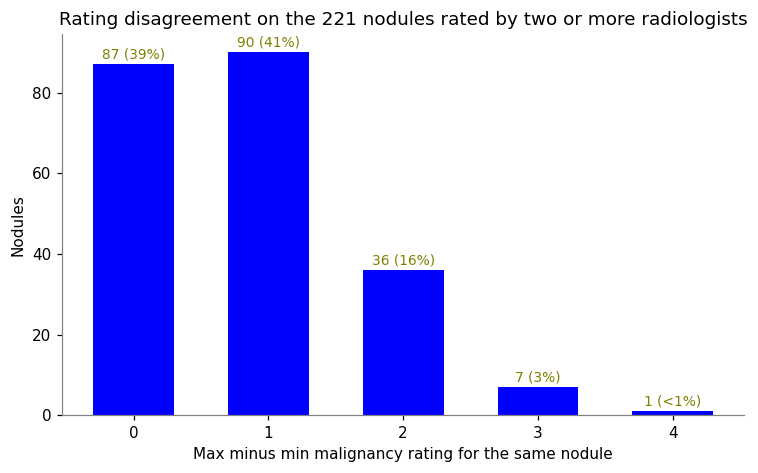

768 unique rated nodules, 221 rated by more than one radiologist
Range of 2 or more: 44 (20%)
Rated 1 to 2 by one reader and 4 to 5 by another: 21
readers who found it    1    2   3
readers of the scan               
1                     162    0   0
2                     233  112   0
3                     152   65  44
            count  mean
RadID_real             
1             281  2.22
2             119  2.09
3             105  1.57
4             227  2.72
5             301  2.18
                 mean  median  max
label 4 or more    20      20   58
label 2 or less    99     100   81
non integer       101      78    0


In [ ]:
BLUE, ORANGE, GREY, OLIVE = "blue", "orange", "grey", "olive"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GREY,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": "w",
    "grid.linewidth": 0.8,
    "axes.titlesize": 12,
    "axes.titleweight": "normal",
    "figure.dpi": 110,
})

train_nodules_gt = pd.read_csv(find_file('trainNodules_gt.csv'))
train_cts = pd.read_csv(find_file('trainCTs.csv'))
readings = train_nodules[["LNDbID", "RadID", "FindingID"]].copy()
readings["malignancy"] = combined_df["malignancy"].values
readings["diam_mm"] = combined_df["diam_mm"].values
readings = readings.set_index(["LNDbID", "RadID", "FindingID"])

rows = []
for lesion_id, lesion in train_nodules_gt[train_nodules_gt["Nodule"] == 1].iterrows():
    for rad, finding in zip(str(lesion["RadID"]).split(","), str(lesion["RadFindingID"]).split(",")):
        rows.append((lesion_id, lesion["LNDbID"], int(rad), int(finding)))
lesion_readings = pd.DataFrame(rows, columns=["lesion", "LNDbID", "RadID", "FindingID"])
lesion_readings = lesion_readings.join(readings, on=["LNDbID", "RadID", "FindingID"])
assert lesion_readings["diam_mm"].notna().all()  # every reading was matched to a nodule row

per_lesion = (lesion_readings.dropna(subset=["malignancy"])
              .groupby("lesion")["malignancy"].agg(["count", "min", "max", "mean", "median"]))
multi = per_lesion[per_lesion["count"] >= 2].copy()
multi["range"] = (multi["max"] - multi["min"]).astype(int)

counts = multi["range"].value_counts().reindex(range(5), fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(counts.index, counts.values, width=0.6, color=BLUE)
for bar, n in zip(bars, counts.values):
    share = f"{n / len(multi):.0%}" if n / len(multi) >= 0.01 else "<1%"
    ax.text(bar.get_x() + bar.get_width() / 2, n + 1.5, f"{n} ({share})", ha="center", fontsize=9, color=OLIVE)
ax.set_xlabel("Max minus min malignancy rating for the same nodule")
ax.set_ylabel("Nodules")
ax.set_title(f"Rating disagreement on the {len(multi)} nodules rated by two or more radiologists")
plt.show()

print(f"{len(per_lesion)} unique rated nodules, {len(multi)} rated by more than one radiologist")
print(f"Range of 2 or more: {(multi['range'] >= 2).sum()} ({(multi['range'] >= 2).mean():.0%})")
print("Rated 1 to 2 by one reader and 4 to 5 by another:", ((multi["min"] <= 2) & (multi["max"] >= 4)).sum())

# Detection agreement: how many of the scan's readers found each nodule
detection = train_nodules_gt[train_nodules_gt["Nodule"] == 1].merge(train_cts, on="LNDbID")
print(pd.crosstab(detection["RadN"], detection["AgrLevel"],
                  rownames=["readers of the scan"], colnames=["readers who found it"]))

# Reader effect on the ratings
print(combined_df[combined_df['Nodule'] == 1].groupby("RadID_real")["malignancy"].agg(["count", "mean"]).round(2))

# How the aggregation rule changes the label of the multi reader nodules
print(pd.DataFrame({rule: {"label 4 or more": (multi[rule] >= 4).sum(),
                           "label 2 or less": (multi[rule] <= 2).sum(),
                           "non integer": (multi[rule] % 1 != 0).sum()}
                    for rule in ["mean", "median", "max"]}))

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Of the 768 unique nodules with at least one rating, only 221 were rated by more than one radiologist, so this histogram describes less than a third of the data. Within those, agreement is reasonable but far from perfect. 87 nodules (39%) got exactly the same rating from everyone, and another 90 (41%) differ by one point, which on a subjective 1 to 5 scale is close to noise. The remaining 20% differ by two points or more, and 21 nodules were called benign (1 or 2) by one reader and suspicious (4 or 5) by another. For those, the binary label depends entirely on how we aggregate.
  </p>
  <p>
    The histogram also understates the real disagreement, because it only includes nodules that more than one reader actually found. In scans read by two radiologists, 233 nodules were found by only one of them and 112 by both. In scans read by three, only 44 of 261 nodules were found by all three. Radiologists disagree far more on whether a nodule is there than on how malignant it looks. The same goes for nodule versus non-nodule: <strong>trainNodules_gt.csv</strong> never merges a nodule call with a non-nodule call, so that kind of disagreement cannot even be measured from this file. There is also a clear reader effect: R3 has a mean rating of 1.57 and R4 of 2.72, and R4 alone gave 95 of the 262 threes. Since 71% of nodules have a single reader, their label partly reflects who happened to read the scan, and no aggregation rule can correct for that.
  </p>
  <p>
    On aggregation, the choice is less open than it looks. With two readers the median is just the mean, so the two only differ on the 44 nodules with three readers, and the counts barely move (20 nodules at 4 or above with either rule). The mean does produce half values in 101 of the 221 cases, so the binarisation threshold has to be stated explicitly, especially around 3. The maximum would raise the multi reader nodules labelled 4 or 5 from 20 to 58, almost three times as many positives in that subset. Clinically it is the cautious choice, since one suspicious read is enough to flag a nodule, but it also amplifies reader bias, and it gives nodules seen by three readers more chances to be labelled positive than nodules seen by one, which is an artefact of the annotation process and not of the nodule. Therefore the mean is the more defensible default.
  </p>
  <p>
    For most parameters, we'll use a special function <strong>'aggregate_columns'</strong> which will adapt our result based on the different scenarios and combinations of values attributed by radiologists. However, for <i>diameter</i> and <i>volume</i> calculations, we'll consider the masks of the nodules, and use a grouped mask to measure them.
  </p>
</div>

In [ ]:
table_csv = table_csv[table_csv['category'] == 1]
cols = ['malignancy', 'lobulation', 'spiculation']
table_csv[cols] = table_csv[cols].replace(0, np.nan)

grouped_csv = table_csv.groupby(['scan_id', 'finding_id'], as_index=False).agg({
    'dataset' : 'first',
    'x': lambda s: aggregate_columns(s, mode = "coordinate"),
    'y': lambda s: aggregate_columns(s, mode = "coordinate"),
    'z': lambda s: aggregate_columns(s, mode = "coordinate"),
    'category': 'first',
    'calcification': lambda s: aggregate_columns(s, start_value=1, end_value=6),
    'internalstructure': lambda s: aggregate_columns(s, start_value=1, end_value=4),
    'lobulation': lambda s: aggregate_columns(s, start_value=1, end_value=5),
    'margin': lambda s: aggregate_columns(s, start_value=1, end_value=5),
    'sphericity': lambda s: aggregate_columns(s, start_value=1, end_value=5),
    'spiculation': lambda s: aggregate_columns(s, start_value=1, end_value=5),
    'subtlety': lambda s: aggregate_columns(s, start_value=1, end_value=5),
    'malignancy': lambda s: aggregate_columns(s, start_value=1, end_value=5),
    'lobe': lambda x: x.mode()[0],                   
    'volume': lambda s: aggregate_columns(s, mode = "volume"),        
    'texture': lambda s: aggregate_columns(s, start_value=1, end_value=5),
    'diam_mm': lambda s: aggregate_columns(s, mode = "coordinate"),
    'fleischner': lambda s: aggregate_columns(s, start_value=0, end_value=3),
    })

In [ ]:
grouped_csv.to_csv('lndb_processed.csv', index=False)
print('Saved successfully:', grouped_csv.shape)

Saved successfully: (659, 20)


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Regarding our custom aggregation function, we have considered slightly different measures for different data types.
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Nodule coordinates:</strong> if the distance between annotated coordinates is less than 3 voxels, we use the mean value. However, for a big range of values, we consider the furthest to be an outlier if the other two are close to eachother, and ignore it in the calculation of the mean.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Visual Characteristics:</strong>  If there is a big disagreement between radiologists, we give preference to a slightly higher result to guarantee that alarming values are not ignored by performing a simple mathematical mean. If the values tend to be high, we use only the high values for the mean. If the values tend to be low, we use the maximum of the low values. If two radiologists gave the same value but a 3rd disagrees, we use the most common value.</li>
  </ul>
  <p>
    Every nodule is characterized now. We have 659 indivudual nodules, by CT Scan, usable for our predictions. In total, we have 212 CT Scans with at least one nodule, with an average of 3.1 nodules per scan. 
  </p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Analysis of Nodule Diameter
  </h3>
</div>

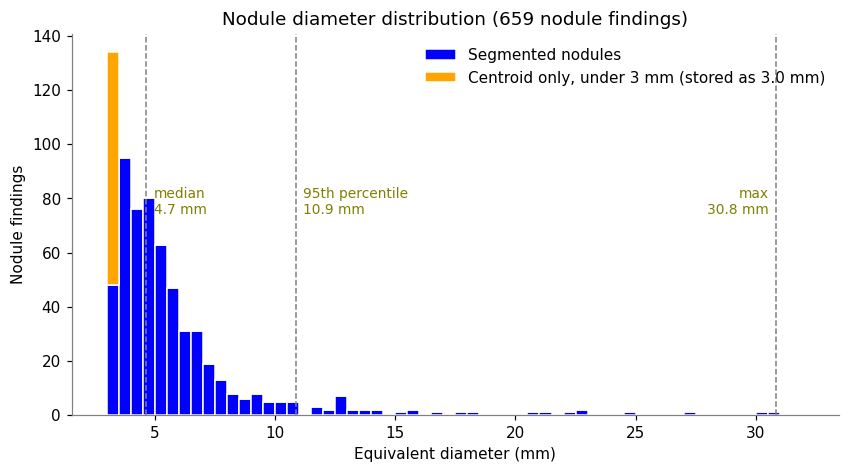

86 of 659 nodules sit exactly on the 3.0 mm placeholder
9 nodules above 20 mm, 7 above the 99th percentile


,all nodules,segmented only
count,659.00,573.00
mean,5.49,5.86
std,3.31,3.39
min,3.00,3.04
50%,4.66,4.90
90%,8.14,8.72
95%,10.88,12.42
99%,21.60,22.24
max,30.85,30.85


In [ ]:
# Nodules under 3 mm were only marked with a centroid and were given the volume of a 3 mm sphere, 
# so a diameter of exactly 3.0 mm is a placeholder rather than a measurement.
placeholder = np.isclose(grouped_csv["diam_mm"], 3.0)
diam_all = grouped_csv["diam_mm"]
diam_seg = diam_all[~placeholder]
p50, p95, dmax = diam_all.median(), diam_all.quantile(0.95), diam_all.max()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist([diam_seg, diam_all[placeholder]], bins=np.arange(3, 32.5, 0.5), stacked=True,
        color=[BLUE, ORANGE], edgecolor="white", linewidth=1,
        label=["Segmented nodules", "Centroid only, under 3 mm (stored as 3.0 mm)"])
top = ax.get_ylim()[1]
for value, name, align in [(p50, "median", "left"), (p95, "95th percentile", "left"), (dmax, "max", "right")]:
    ax.axvline(value, color=GREY, linestyle="--", linewidth=1)
    offset = 0.3 if align == "left" else -0.3
    ax.text(value + offset, top * 0.6, f"{name}\n{value:.1f} mm", ha=align, va="top", fontsize=9, color=OLIVE)
ax.set_xlabel("Equivalent diameter (mm)")
ax.set_ylabel("Nodule findings")
ax.set_title(f"Nodule diameter distribution ({len(grouped_csv)} nodule findings)")
ax.legend(frameon=False)
plt.show()

print(f"{placeholder.sum()} of {len(grouped_csv)} nodules sit exactly on the 3.0 mm placeholder")
print(f"{(diam_all > 20).sum()} nodules above 20 mm, {(diam_all > diam_all.quantile(0.99)).sum()} above the 99th percentile")
pd.DataFrame({
    "all nodules": diam_all.describe(percentiles=[0.5, 0.9, 0.95, 0.99]),
    "segmented only": diam_seg.describe(percentiles=[0.5, 0.9, 0.95, 0.99]),
}).round(2)

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The histogram shows that 86 of the 659 nodules (13%) have a diameter of exactly 3.0 mm, which is also both the minimum and the 5th percentile. In this dataset, nodules smaller than 3 mm were only marked with a centroid and never segmented; they were given the volume of a 3 mm sphere, the same 14.137 mm³ placeholder used for non-nodules. Their true size is somewhere below 3 mm. These nodules also have no segmentation mask, so any feature computed inside the mask, which includes everything pyradiomics extracts, is unavailable for them. 
  </p>
    Something else looks slightly odd: the smallest segmented nodule has an equivalent diameter of 3.04 mm. The 3 mm rule refers to the largest in plane dimension, so a flat or elongated nodule could qualify and still have an equivalent diameter below 3 mm. Seeing none at all suggests the threshold was applied to the segmented volume in some way. It does not change the analysis, but it is worth knowing if we ever compare these diameters with the ones in the radiology reports.
  </p>
  <p>
    Once the placeholder is set aside, the nodules are small and the distribution is strongly right skewed. The median is 4.7 mm (4.9 mm for segmented nodules only), and 95% of the nodules are below 10.9 mm (12.4 mm for segmented only). The tail is long but thin. Only 9 nodules are above 20 mm and the largest is 30.8 mm, so if we had sized things around the maximum we would be designing for a handful of cases.
  </p>
  <p>
    The patch size has to contain the biggest nodules with some margin, since we want spiculation and lobulation to show up. Since nodEqDiam assumes a sphere, and an elongated nodule extends further than its equivalent diameter along its long axis, the patch needs some margin on top of these numbers. The default in extractCube is a 51 mm cube. That leaves about 19 mm of context on each side of a 12.2 mm nodule and still about 10 mm around the 31 mm one, so nothing in the training set gets cut. The problem is at the other end. A median 4.8 mm nodule covers less than a tenth of the cube width, and the rest of the patch is surrounding lung, vessels and sometimes chest wall. For a CNN, a patch of around 32 mm would keep the p95 nodule with about 10 mm of margin on each side and give the nodule much more weight in the input. The cost is that roughly 1% of nodules, the ones above about 21.6 mm, would be left with very little surrounding context. That could be handled with a second, larger scale or simply accepted. For radiomics. the patch size matters much less, since features are computed inside the mask, as long as the patch fully contains it. 
  </p>
  <p>
    The real decision here is deciding whether we will use <strong>radiomics or deep learning</strong>.
  </p>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Analysis of Voxel Spacing Accross Scans
  </h3>
</div>

z spacing read from 294 scan headers


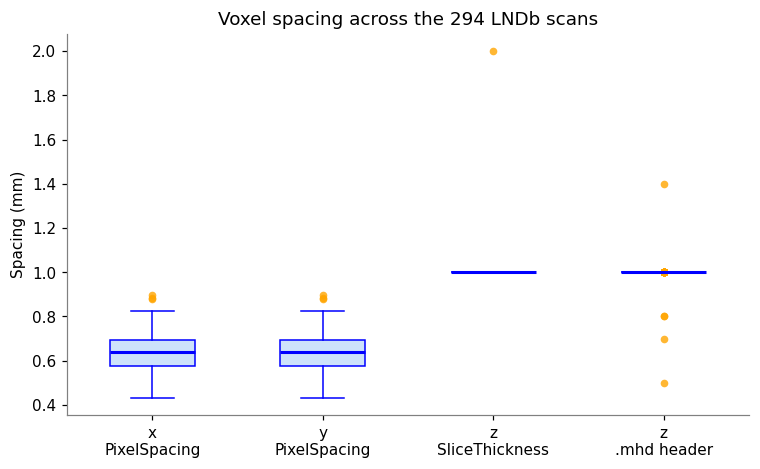

       spacing_x  spacing_y  SliceThickness  spacing_z_header
count    294.000    294.000         294.000           294.000
mean       0.632      0.632           1.003             0.997
std        0.088      0.088           0.058             0.044
min        0.433      0.433           1.000             0.500
25%        0.574      0.575           1.000             1.000
50%        0.640      0.640           1.000             1.000
75%        0.691      0.691           1.000             1.000
max        0.895      0.895           2.000             1.400
Largest x/y difference within a scan: 0.0005 mm
 LNDbID  SliceThickness  spacing_z_header    ManufacturerModelName
    115               1          0.700000 SOMATOM Definition Flash
    209               1          0.500000            SOMATOM go.Up
    268               2          1.400000 SOMATOM Definition Flash
    270               1          0.800062            SOMATOM go.Up
    284               1          0.800000 SOMATOM Definitio

In [ ]:
acq = pd.read_csv(find_file("LNDbAcqParams.csv"))
train_cts = pd.read_csv(find_file("trainCTs.csv"))
# In plane spacing comes as the DICOM PixelSpacing string "[row spacing, column spacing]", so [y, x]
pixel_spacing = acq["PixelSpacing"].apply(ast.literal_eval).apply(lambda v: [float(x) for x in v])
acq["spacing_y"] = pixel_spacing.str[0]
acq["spacing_x"] = pixel_spacing.str[1]
# Along z the file only has SliceThickness, which is not the same thing as the distance between slices.
# The actual slice interval is in each .mhd header (ElementSpacing, in x y z order), and reading the header text is enough.
z_header = {}
for mhd_path in Path("../data").rglob("LNDb-*.mhd"):
    scan_id = mhd_path.stem.replace("LNDb-", "")
    if not scan_id.isdigit() or int(scan_id) in z_header: continue # skips masks and duplicate copies of a scan
    for line in mhd_path.read_text().splitlines():
        if line.startswith("ElementSpacing"): z_header[int(scan_id)] = float(line.split("=")[1].split()[2])
acq["spacing_z_header"] = acq["LNDbID"].map(z_header)
print(f"z spacing read from {len(z_header)} scan headers")

columns = ["spacing_x", "spacing_y", "SliceThickness", "spacing_z_header"]
labels = ["x\nPixelSpacing", "y\nPixelSpacing", "z\nSliceThickness", "z\n.mhd header"]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([acq[c].dropna() for c in columns], tick_labels=labels, widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE),
           medianprops=dict(color=BLUE, linewidth=2),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
           flierprops=dict(marker="o", markersize=5, markerfacecolor=ORANGE, markeredgecolor="none", alpha=0.8))
ax.set_ylabel("Spacing (mm)")
ax.set_title(f"Voxel spacing across the {len(acq)} LNDb scans")
plt.show()

print(acq[columns].describe().round(3))
print("Largest x/y difference within a scan:", (acq["spacing_x"] - acq["spacing_y"]).abs().max().round(4), "mm")

odd_z = acq[~np.isclose(acq["spacing_z_header"], 1.0, atol=0.01)]
print(odd_z[["LNDbID", "SliceThickness", "spacing_z_header", "ManufacturerModelName"]].to_string(index=False))
print("of which in the training set:", odd_z["LNDbID"].isin(train_cts["LNDbID"]).sum())

anisotropy = acq["spacing_z_header"] / acq["spacing_x"]
print(f"z / x spacing ratio: median {anisotropy.median():.2f}, from {anisotropy.min():.2f} to {anisotropy.max():.2f}")
print(acq["ManufacturerModelName"].value_counts().to_string())

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    <strong>'LNDbAcqParams.csv'</strong> has no <i>SpacingX, SpacingY</i> or <i>SpacingZ</i> columns. The in plane spacing is a single PixelSpacing column holding a two element list stored as text, and along z there is only SliceThickness. Slice thickness and slice spacing are different DICOM quantities, because slices can be reconstructed with overlap, so for z we read ElementSpacing from each .mhd header. That is what utils.readMhd returns and what the rest of the pipeline actually uses.
  </p>
  <p>
    In plane, x and y are the same within each scan (the largest difference is below 0.001 mm), but they vary a lot between scans, from 0.43 mm to 0.89 mm with a median of 0.64 mm. With a fixed 512x512 matrix, the pixel size follows the reconstruction field of view, <strong>which is adjusted to each patient, so this variation is mostly about body size and not different protocols.</strong> 
  </p>
  <p>
    Along z, the picture is the opposite. SliceThickness is 1 mm in 293 of the 294 scans, and the header spacing is 1 mm in 289. The five exceptions (0.5, 0.7, 0.8, 0.8 and 1.4 mm) are all training scans, and only one of them, the 1.4 mm scan reconstructed with 2 mm slices, would be caught by looking at SliceThickness. The other four would go unnoticed if we trusted the CSV, which is a good reason to always take spacing from the image header. All the scans come from three Siemens models, so the acquisition is fairly homogeneous overall.
  </p>
  <p>
    The consequence is that the voxels are anisotropic in practically every scan. The z spacing is typically 1.55 times the in plane spacing and up to 2.3 times, and in the one scan with 0.5 mm slices it goes the other way. <strong>Without resampling, a 6 mm nodule is about 14 pixels wide in one scan and 7 in another</strong>, and texture features that compare neighbouring voxels (GLCM and similar) would be mixing different physical distances depending on direction and on the scan. We must resample to a common isotropic spacing before feature extraction; it is what the IBSI guidelines recommend for 3D radiomics. 
  </p>
  <p>
    The harder question is the target. Resampling to 1 mm would throw away in plane resolution in almost every scan, and for the many nodules between 3 and 5 mm that leaves only a few voxels per axis. Something close to the median in plane spacing, around 0.6 to 0.7 mm, seems a better compromise. Upsampling along z does not add information, but it keeps the geometry consistent. extractCube already does this implicitly: it takes a 51 mm cube and resizes it to 80 voxels, an isotropic grid of about 0.64 mm. If we also use pyradiomics, resampledPixelSpacing should be set to the same value so both paths agree. Resampling does not solve everything, though. The reconstruction kernel also varies (mostly Br64f and B50f, with some I50f iterative reconstructions), and kernel differences affect texture features at least as much as spacing does. We now have to understand if there is the need to minimise this problem or if it is a limitation to identify.
  </p>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Analysis of Malignancy Label Coverage
  </h3>
</div>

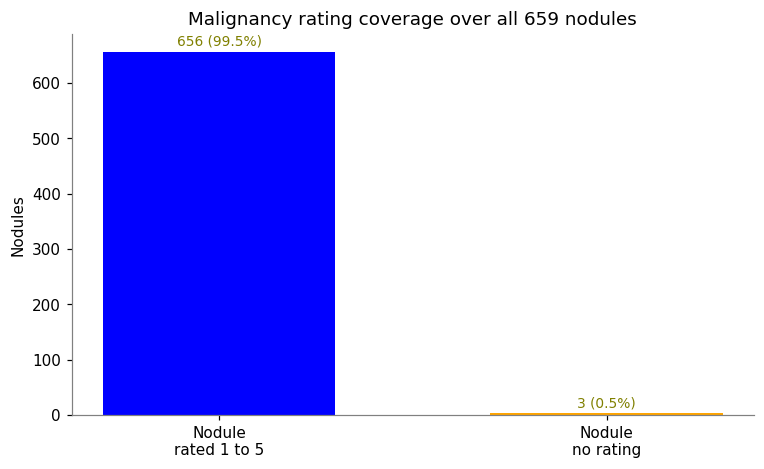

 scan_id  finding_id  diam_mm
      85           1 3.334297
     121           5 4.659270
     122           2 4.929141
Nodule coverage: 99.5%
Rated nodules without a mask (under 3 mm): 86
Rated nodules with a mask: 570


In [ ]:
rated = grouped_csv["malignancy"].notna()

coverage = pd.Series({"Nodule\nrated 1 to 5": (rated).sum(),"Nodule\nno rating": (~rated).sum(),})
assert coverage.sum() == len(grouped_csv)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(coverage.index, coverage.values, width=0.6, color=[BLUE, ORANGE, GREY])
for bar, n in zip(bars, coverage.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 12, f"{n} ({n / len(grouped_csv):.1%})", ha="center", fontsize=9, color=OLIVE)
ax.set_ylabel("Nodules")
ax.set_title(f"Malignancy rating coverage over all {len(grouped_csv)} nodules")
plt.show()

print(grouped_csv.loc[~rated, ["scan_id", "finding_id", "diam_mm"]].to_string(index=False))
has_mask = ~np.isclose(grouped_csv["diam_mm"], 3.0)
print(f"Nodule coverage: {(rated).sum() / len(grouped_csv):.1%}")
print(f"Rated nodules without a mask (under 3 mm): {(rated & ~has_mask).sum()}")
print(f"Rated nodules with a mask: {(rated & has_mask).sum()}")

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Across all nodules, only 3 malignancy ratings are missing, in scans 85, 121 and 122. Coverage for nodules is 99.5%. The three unrated nodules are too few to be worth imputing and can simply be dropped from the classification set. More importantly, having a rating does not mean a finding is usable by every part of the pipeline. 86 of the rated nodules are the under 3 mm findings from the diameter plot, which have a label but no mask. Only 570 rated nodules come with a segmentation, and if features are extracted from masks that is the real size of the labelled set.
  </p>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Analysis of Malignancy Class Distribution
  </h3>
</div>

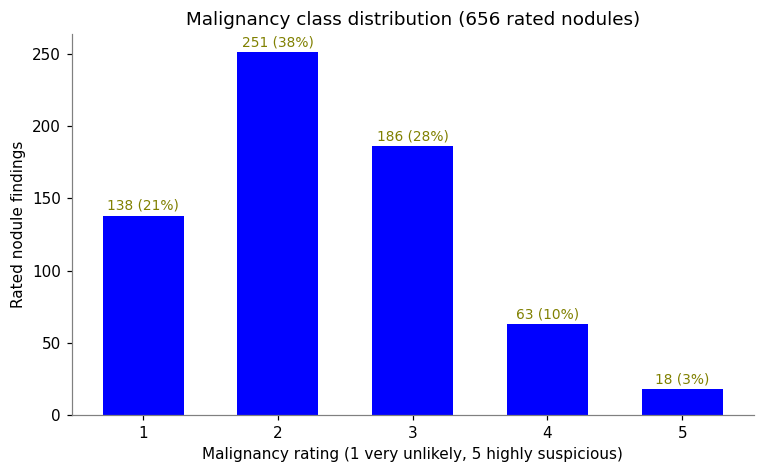

Always predicting the majority class, 5 classes: 38.3% accuracy
Always predicting benign, binary without the 3s: 82.8% accuracy
Always predicting benign, binary with 3 counted as benign: 87.7% accuracy
mean
1    230
2    279
3    182
4     60
5     14
Name: count, dtype: int64
Share of 4 and 5 with a mask: 10.9% of 570


In [ ]:
class_counts = grouped_csv["malignancy"].apply(np.ceil).value_counts().reindex([1.0, 2.0, 3.0, 4.0, 5.0]).astype(int)
total = class_counts.sum()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar([1, 2, 3, 4, 5], class_counts.values, width=0.6, color=BLUE)
for bar, n in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 4, f"{n} ({n / total:.0%})", ha="center", fontsize=9, color=OLIVE)
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel("Malignancy rating (1 very unlikely, 5 highly suspicious)")
ax.set_ylabel("Rated nodule findings")
ax.set_title(f"Malignancy class distribution ({total} rated nodules)")
plt.show()

benign, indeterminate, suspicious = class_counts[[1.0, 2.0]].sum(), class_counts[3.0], class_counts[[4.0, 5.0]].sum()
print(f"Always predicting the majority class, 5 classes: {class_counts.max() / total:.1%} accuracy")
print(f"Always predicting benign, binary without the 3s: {benign / (benign + suspicious):.1%} accuracy")
print(f"Always predicting benign, binary with 3 counted as benign: {(benign + indeterminate) / total:.1%} accuracy")

# Same distribution per unique nodule, averaging readers and rounding to the nearest class
print(pd.cut(per_lesion["mean"], [0, 1.5, 2.5, 3.5, 4.5, 5], labels=[1, 2, 3, 4, 5]).value_counts().sort_index())

# And restricted to readings that have a segmentation
with_mask = grouped_csv[~placeholder]["malignancy"].dropna()
print(f"Share of 4 and 5 with a mask: {(with_mask >= 4).mean():.1%} of {len(with_mask)}")

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The distribution is skewed towards the benign end. Ratings 1 and 2 account for 389 of the 656 rated nodules (59%), 3 for 186 (28%), and 4 and 5 together for only 81 (12%). Class 5 has just 18 nodules. This backs up our decision not to rely on accuracy alone. A model that always predicts benign would get a high value of accuracy while missing every suspicious nodule. Accuracy would reward exactly the behaviour which is not our main goal
  </p>
  <p>
    <strong>Recall on the suspicious class, balanced accuracy, F1 and ROC AUC</strong> say much more, and with these few positives the precision recall curve is more honest than ROC, together with the confusion matrix itself. If we keep the five classes, they are ordinal, so a weighted kappa would penalise predicting 1 for a 5 more than predicting 4 for a 5, which plain accuracy treats as the same mistake.
  </p>
  <p>
    Two things should shape the binary definition. First, class 3 is the second largest class and means indeterminate, not malignant. Moving it to either side changes the positive rate a lot, so it needs a deliberate decision, and it is also the class where reader bias is strongest, with R4 contributing over a third of the threes. Second, the findings under 3 mm are almost all 1s and 2s and have no mask. If they are excluded for that reason, the share of 4 and 5 rises, so the imbalance is a bit softer on the data we will actually use, but it does not go away. Class weights or resampling during training will still be needed, and the folds should be stratified by class as well as grouped by scan.

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Formalizing the Malignancy Label per Nodule
  </h3>
</div>

In [ ]:
# One row per unique nodule, carrying position, volume, and the malignancy statistics. 
mean_df = table_csv.groupby(['scan_id', 'finding_id'])["malignancy"].agg(["count", "min", "max", "mean", "median"])
nodule_labels = (grouped_csv[["scan_id", "finding_id", "x", "y", "z", "volume", "malignancy"]].rename(columns={"malignancy": "malignancy_agg"})
                  .join(mean_df, on = ['scan_id', 'finding_id'], how="left")
                  .rename(columns={"mean": "malignancy_mean", "count": "n_raters"}))
nodule_labels.insert(0, "dataset", "LNDb")
print(f"{nodule_labels['malignancy_mean'].isna().sum()} nodules have no rated reading and stay unlabelled")

# The 2.5 / 3.5 split already used informally in section 5, made explicit and applied to the continuous
# per-nodule mean rather than to individual readings.
nodule_labels["label_ternary"] = pd.cut(nodule_labels["malignancy_mean"], bins=[0, 2.5, 3.5, 5],
                                        labels=["benign", "indeterminate", "malignant"])

# The strict two class view some baselines will want. Indeterminate nodules get NaN here, not a dropped
# row: nodule_labels keeps every nodule, and excluding the indeterminate band for a given model becomes
# an explicit nodule_labels["label_binary"].notna() filter at that model's own boundary.
nodule_labels["label_binary"] = nodule_labels["label_ternary"].map({"benign": 0, "malignant": 1})

print("\nTernary label:\n", nodule_labels["label_ternary"].value_counts(dropna=False).to_string())
print("\nBinary label (NaN = indeterminate or unrated):\n",
      nodule_labels["label_binary"].value_counts(dropna=False).to_string())

n_rated = nodule_labels["malignancy_mean"].notna().sum()
n_indeterminate = (nodule_labels["label_ternary"] == "indeterminate").sum()
print(f"\n{n_indeterminate} of {n_rated} rated nodules ({n_indeterminate / n_rated:.1%}) sit in the "
      f"indeterminate band; a plain 3-vs-rest exclusion rule would have dropped all of them from training")

nodule_labels.to_csv("lndb_nodule_labels.csv", index_label="lesion")
nodule_labels.head()

                    count  min  max      mean  median
scan_id finding_id                                   
1       1               3  2.0  2.0  2.000000     2.0
        2               1  2.0  2.0  2.000000     2.0
2       1               3  1.0  2.0  1.333333     1.0
        2               3  1.0  1.0  1.000000     1.0
        3               2  1.0  3.0  2.000000     2.0


ValueError: cannot join with no overlapping index names

Decisions:

**Use the mean, not the max.** Section 4 showed the max is not a neutral choice: it nearly tripled the count of positive multi-reader nodules (20 to 58), and it gives nodules read by three radiologists more chances of ending up positive than nodules read by one, which is an artefact of who happened to read the scan, not a property of the nodule. The mean also absorbs the known reader effect directly (R4 rating far higher on average than R3) instead of letting one biased reader decide the label on their own. It also matches how the LIDC-IDRI literature we compare against later builds its own labels: Causey et al. (2018) assign each nodule "the average of the malignancy ratings assigned by the radiologists who annotated the nodule, rounded to the nearest integer," then drop the resulting class 3 nodules from their binary comparison. Rounding an average to the nearest integer is the same thing as cutting it at 1.5 / 2.5 / 3.5 / 4.5, so their class 3 is our 2.5 to 3.5 indeterminate band; we just keep it as a continuous mean and an explicit band instead of rounding it away. (Talvez explicar esta parte melhor). In conclusion, our understanding of the topic is that the max amplifies reader bias and rewards nodules that happened to be seen by more professionals. With that in mind and also considering the literature cited, we consider the mean to be a better trade-off option.

**The scale is ordinal, and the classes are imbalanced.** Malignancy 1 to 5 is a rating of increasing likelihood, not five unrelated categories, so predicting 1 for a true 5 should count as a worse mistake than predicting 4 for a true 5, something plain accuracy cannot express ( webgrafia Cohen, 1968, on weighted agreement between ordinal ratings). Combined with the idea already shown in section 5, ratings 1 and 2 covering 62% of readings against 13% for 4 and 5, accuracy also rewards a model that always predicts benign, which is exactly the failure mode we want the evaluation to expose rather than hide (He & Garcia, 2009, on why imbalanced problems need metrics beyond accuracy - colocar webgrafia).

**Class 3 cannot be dropped without a deliberate decision.** It is the second largest class, 25% of readings, it is the class most shaped by a single reader's bias (R4 alone gave over a third of all the 3s), and, as we have understood in the literature and explain in the next section in more detail, the literature built specifically around this labelling problem treats discarding it outright as the weaker default rather than the safer one (Lei et al., 2020; Zhang et al., 2022; Baltatzis et al., 2021).

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The three columns are views of one number, not three different labelling schemes. <strong>'malignancy_mean'</strong> is what should feed a model whose output also has to serve as the competition's 1 to 5 prediction, since it keeps the full ordinal scale. <strong>'label_ternary'</strong> and <strong>'label_binary'</strong> are read off that same number afterwards, purely for reporting: computing balanced accuracy, F1 or a confusion matrix against <strong>'label_ternary'</strong>, or against <strong>'label_binary.notna()'</strong> for a stricter two class comparison, gives us numbers that a clinician, or the accuracy and AUC figures quoted in the related work section of the project brief, can actually be read against, without ever having trained on a version of the data missing a quarter of its nodules.
  </p>
  <p>
    One thing worth checking once this cell has actually run against a consistent <strong>'lndb_processed.csv'</strong>: 25% of individual readings are rated 3 (section 5), but that reading level share is not the same number as the share of nodules whose <strong>'malignancy_mean'</strong> lands in the indeterminate band. Averaging pulls single-reader nodules toward whatever that one reader said, so a nodule read once as a 3 stays there, while a nodule read by several radiologists only ends up near 3 if their ratings disagree in a way that happens to average out, or if several of them independently land close to the middle. The count printed above the ternary breakdown is the number that actually matters for deciding how much data an exclusion rule would cost, not the reading level 25%, and it is worth re-checking whenever <strong>'per_lesion'</strong> changes.
  </p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    References
  </h3>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"> Baltatzis, V., Bintsi, K.-M., Le Folgoc, L., Martinez Manzanera, O. E., Ellis, S., Nair, A., Desai, S., Glocker, B., & Schnabel, J. A. (2021). <i>The Pitfalls of Sample Selection: A Case Study on Lung Nodule Classification</i>. PRIME, MICCAI 2021. https://arxiv.org/abs/2108.05386 - shows that sample-selection choices on this same family of datasets can outweigh model choice in reported results, which is why every threshold used here is stated and printed explicitly.</li>
    <li style="margin-bottom: 8px;"> Causey, J. L., Zhang, J., Ma, S., Jiang, B., Qualls, J. A., Politte, D. G., Prior, F., Zhang, S., & Huang, X. (2018). <i>Highly accurate model for prediction of lung nodule malignancy with CT scans</i>. Scientific Reports, 8, 9286 - builds each nodule's label from "the average of the malignancy ratings assigned by the radiologists who annotated the nodule, rounded to the nearest integer" and excludes the resulting class 3 from its S1-vs-S45 and S12-vs-S45 binary comparisons; the same averaging step used here, with class 3 rounded away instead of kept as an explicit band.</li>
    <li style="margin-bottom: 8px;"> Cohen, J. (1968). <i>Weighted kappa: Nominal scale agreement with provision for scaled disagreement or partial credit</i>. Psychological Bulletin, 70(4), 213–220. https://doi.org/10.1037/h0026256 - supports treating the 1 to 5 malignancy scale as ordinal rather than nominal when scoring agreement or model error.</li>
    <li style="margin-bottom: 8px;"> He, H., & Garcia, E. A. (2009). <i>Learning from Imbalanced Data.</i> IEEE Transactions on Knowledge and Data Engineering, 21(9), 1263–1284. https://doi.org/10.1109/TKDE.2008.239 - motivates the move away from accuracy given how skewed the malignancy classes are. </li>
    <li style="margin-bottom: 8px;"> Lei, Y., Zhu, H., Zhang, J., & Shan, H. (2020). <i>Meta Ordinal Regression Forest For Learning with Unsure Lung Nodules</i>. IEEE International Conference on Bioinformatics and Biomedicine (BIBM). https://arxiv.org/abs/2012.03480 — motivates keeping class 3 / "unsure" nodules in training through ordinal regression instead of a binary exclusion rule.</li>
    <li style="margin-bottom: 8px;"> McNitt-Gray, M. F., Armato, S. G., Meyer, C. R., Reeves, A. P., McLennan, G., Pais, R. C., Freymann, J., Brown, M. S., Engelmann, R. M., Bland, P. H., Laderach, G. E., Piker, C., Guo, J., Towfic, Z., Qing, D. P.-Y., Yankelevitz, D. F., Aberle, D. R., van Beek, E. J. R., MacMahon, H., Kazerooni, E. A., Croft, B. Y., & Clarke, L. P. (2007). <i>The Lung Image Database Consortium (LIDC) Data Collection Process for Nodule Detection and Annotation</i>. Academic Radiology, 14(12), 1464–1474 - establishes malignancy as a per-radiologist ordinal rating, which is why it is treated as one continuous quantity here rather than a category from the start, and why several independent readers are pooled per nodule rather than kept as separate examples. </li>
    <li style="margin-bottom: 8px;"> Zhang, H., Gu, X., Zhang, M., Yu, W., Chen, L., Wang, Z., Yao, F., Gu, Y., & Yang, G.-Z. (2022). <i>Re-thinking and Re-labeling LIDC-IDRI for Robust Pulmonary Cancer Prediction</i>. https://arxiv.org/abs/2207.14238 - compares 6 different ways of turning LIDC's average malignancy score into a binary label (excluding the uncertain average outright, or sliding the division threshold across it), and shows the resulting bias toward false positives shrinks but does not disappear as the threshold moves; quantifies the labelling bias this section is designed to avoid. </li>
  </ul>
</div>
